# TheMove — Final Project: ML Evaluation and Local Venue Catalog

**Team:** Ola Oluwa James-Owolabi and Emmanuella Turkson  
**Environment:** Google Colab  
**Purpose:** Reproduce the group-aware machine-learning comparisons and produce the Little Rock activity CSV used by the Streamlit prototype in **one notebook**.

> **Important distinction:** The group-decision research model predicts preferences for anonymous D1–D10 destinations. The real Little Rock venue catalog comes from OpenStreetMap geographic data and **is not scored by that trained ML model**. Local category/distance matching is rule-based.

### Input files
- **Required for ML:** `Group-decision-making-dataset-main.zip` or extracted group CSVs and `group_composition.pkl` (or set `DATA_ROOT` in the dataset-discovery cell).
- **Optional for local venue export:** `arkansas-261028-free.gpkg.zip` (or extracted `arkansas.gpkg`).
- The restaurant-consumer ZIP is optional context and does not provide labels for the D1–D10 model.

### How to run
1. Upload the required dataset ZIP(s) into the Colab runtime (usually `/content`), or mount Drive and configure `DATA_ROOT`.
2. Choose **Runtime → Restart session and run all**.
3. Examine computed evaluation results; do not substitute historical figures without verifying they match.
4. Download the CSV exports, especially `themove_little_rock_places.csv` for the Streamlit app.

**Data note:** Temporary Colab files can disappear when a session is reset. You may need to re-upload the ZIP files.

In [34]:
# 01 | Imports and reproducible settings
from pathlib import Path
import os, zipfile, warnings, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

SEED = 42
np.random.seed(SEED)
DATA_ROOT = Path('/content') if Path('/content').is_dir() else Path.cwd()
# Optional: set EXTRA_DATA_DIR to the folder containing files in mounted Drive.
# For example, EXTRA_DATA_DIR = '/content/drive/MyDrive/TheMove'
EXTRA_DATA_DIR = None
OUTPUT_DIR = DATA_ROOT / 'themove_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Data root:', DATA_ROOT)
print('pandas:', pd.__version__, '| sklearn:', __import__('sklearn').__version__)

Data root: /content
pandas: 2.2.3 | sklearn: 1.6.1


## 1. Discover files uploaded to Colab

The screenshot shows file entries at the filesystem root (`/`) as well as ordinary system folders. Colab uploads are normally stored in `/content`, but the notebook now searches **both `/content` and the top level of `/`**, then inspects ZIP members to find a *complete matching group dataset*. It does not recursively scan your entire operating system or extract the large Arkansas ZIPs.

Only if the group ZIP is no longer present: run the optional upload helper below and upload `Group-decision-making-dataset-main.zip`. If you store data in Google Drive, mount Drive separately and set `EXTRA_DATA_DIR` in Cell 01. Original group ZIP contents are trusted source data; only load the `.pkl` file if you trust its source.

In [35]:
# 02 | Colab file discovery: uploaded archives, extracted folders, or loose CSVs
from pathlib import Path
import zipfile

# OPTIONAL UPLOAD (run only if the ZIP is absent after a runtime reset):
# from google.colab import files
# files.upload()  # Choose Group-decision-making-dataset-main.zip

SEARCH_DIRS = [Path('/content'), Path.cwd(), Path('/')]
if EXTRA_DATA_DIR:
    SEARCH_DIRS.insert(0, Path(EXTRA_DATA_DIR).expanduser())
SEARCH_DIRS = list(dict.fromkeys(p.resolve() for p in SEARCH_DIRS if p.is_dir()))

GROUP_FILES = {'ratings.csv','group_choices.csv','user_features.csv',
               'user_feedback.csv','group_composition.pkl'}
RESTAURANT_FILES = {'rating_final.csv','geoplaces2.csv','userprofile.csv'}

def find_complete_folder(required):
    """Prefer complete, unambiguously matched dataset directories."""
    candidates = []
    for root in SEARCH_DIRS:
        # Top-level files first; root (/) is not searched recursively.
        if all((root / file).is_file() for file in required):
            candidates.append(root)
        if root == Path('/'):
            continue
        # Recursion only in specified data directories; ignore cache/system folders.
        for anchor in ('ratings.csv','group_composition.pkl','rating_final.csv'):
            if anchor not in required:
                continue
            for candidate in root.rglob(anchor):
                parent = candidate.parent
                if all((parent / name).is_file() for name in required):
                    candidates.append(parent)
    # Favor the named source dataset over unrelated ratings.csv files.
    candidates = list(dict.fromkeys(candidates))
    candidates.sort(key=lambda x: (
        not any(token in str(x).lower() for token in ('group-decision','group_decision','themove_group')),
        len(x.parts)
    ))
    return candidates[0] if candidates else None

def find_archives():
    found = []
    for root in SEARCH_DIRS:
        try:
            archives = list(root.glob('*.zip')) if root == Path('/') else list(root.rglob('*.zip'))
        except PermissionError:
            archives = []
        found.extend(archives)
    return list(dict.fromkeys(p.resolve() for p in found))

def archive_contains_group(zip_path):
    try:
        with zipfile.ZipFile(zip_path) as z:
            names = [Path(member.filename) for member in z.infolist() if not member.is_dir()]
            parents = {str(path.parent) for path in names if path.name == 'group_composition.pkl'}
            return any(GROUP_FILES <= {p.name for p in names if str(p.parent)==parent} for parent in parents)
    except (OSError, zipfile.BadZipFile):
        return False

def extract_safe(zip_path, dest):
    """Only extract safe paths, into a separate named folder."""
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        dest_resolved=dest.resolve()
        for member in z.infolist():
            target=(dest / member.filename).resolve()
            if target == dest_resolved or dest_resolved in target.parents:
                z.extract(member,dest)

archives=find_archives()
print('Search locations:', ', '.join(map(str,SEARCH_DIRS)))
print('ZIP files seen:', [p.name for p in archives[:25]])

group_path = find_complete_folder(GROUP_FILES)
if group_path is None:
    for archive in archives:
        if archive_contains_group(archive):
            target=DATA_ROOT/'themove_extracted_group'
            print('Found complete Group Decision-Making archive:',archive)
            extract_safe(archive,target)
            group_path=find_complete_folder(GROUP_FILES)
            if group_path is not None:
                break
if group_path is None:
    # Be explicit about missing companion files, even if loose CSVs are present.
    loose={name:[str(root/name) for root in SEARCH_DIRS if (root/name).is_file()] for name in GROUP_FILES}
    print('Loose files at search roots:',loose)
    raise FileNotFoundError('Could not locate the complete Group Decision-Making dataset. '
                            'Upload Group-decision-making-dataset-main.zip to Colab and rerun Cell 02. '
                            'The separate ratings.csv alone is insufficient without group_composition.pkl.')

restaurant_path=find_complete_folder(RESTAURANT_FILES)
if restaurant_path is None:
    for archive in archives:
        if 'restaurant' in archive.name.lower():
            try:
                extract_safe(archive,DATA_ROOT/'themove_extracted_restaurant')
                restaurant_path=find_complete_folder(RESTAURANT_FILES)
                if restaurant_path: break
            except (OSError, zipfile.BadZipFile) as exc:
                print('Skipping unreadable restaurant archive:',exc)

print('Group dataset:',group_path)
print('Restaurant dataset:',restaurant_path or 'not found — optional')
print('Group files verified:',sorted(GROUP_FILES))

Search locations: /content, /
ZIP files seen: ['dataset_ubicomp2013.zip', 'restaurant+consumer+data.zip', 'arkansas-261028-free.gpkg.zip', 'restaurant+consumer+data (1).zip', 'arkansas-261028-free.shp.zip', 'Group-decision-making-dataset-main.zip', 'dataset_TIST2015.zip']
Group dataset: /content/themove_extracted_group/Group-decision-making-dataset-main
Restaurant dataset: /content/themove_extracted_restaurant
Group files verified: ['group_choices.csv', 'group_composition.pkl', 'ratings.csv', 'user_features.csv', 'user_feedback.csv']


In [36]:
# 03 | Load original, unmodified datasets
ratings = pd.read_csv(group_path / 'ratings.csv')
group_choices = pd.read_csv(group_path / 'group_choices.csv')
user_features = pd.read_csv(group_path / 'user_features.csv')
user_feedback = pd.read_csv(group_path / 'user_feedback.csv')
group_file = group_path / 'group_composition.pkl'
if not group_file.is_file():
    raise FileNotFoundError(f'Missing group composition: {group_file}')
# WARNING: Pickle is executable; only load the trusted research archive.
group_composition = pd.read_pickle(group_file)
assert isinstance(group_composition, dict), 'Expected group_composition.pkl to contain a dictionary.'
if restaurant_path:
    restaurant_ratings = pd.read_csv(restaurant_path / 'rating_final.csv')
    restaurants = pd.read_csv(restaurant_path / 'geoplaces2.csv', encoding='latin-1')
    user_profiles = pd.read_csv(restaurant_path / 'userprofile.csv', encoding='latin-1')
else:
    restaurant_ratings = restaurants = user_profiles = None

for label, df in [('ratings', ratings),('choices',group_choices),('features',user_features),('feedback',user_feedback)]:
    print(f'{label}: {df.shape}; columns = {df.columns.tolist()}')
print('Groups:',len(group_composition))
display(ratings.head(3))

ratings: (2772, 4); columns = ['user', 'item', 'rating', 'rank']
choices: (160, 3); columns = ['group_id', 'item', 'rank']
features: (282, 9); columns = ['user_id', 'gender', 'age', 'opn', 'cns', 'ext', 'agr', 'est', 'experience']
feedback: (282, 5); columns = ['user_id', 'choice_sat', 'difficulty', 'identification', 'similarity']
Groups: 79


,user,item,rating,rank
0,99355,D1,10,1
1,99355,D2,6,5
2,99355,D3,8,3


## 2. Data checks and descriptive analysis

Ratings are 0–10 scores in the tourism dataset, not costs or venue prices. The restaurant dataset's rating scale and users are unrelated, so the two are **not merged** into one recommender.

Missing values (ratings): {'user': 0, 'item': 0, 'rating': 0, 'rank': 0}
Duplicate user-item rows: 0
Rating range: 1 10
Item counts: {'D1': 282, 'D10': 270, 'D2': 282, 'D3': 282, 'D4': 270, 'D5': 270, 'D6': 270, 'D7': 282, 'D8': 282, 'D9': 282}


,count,mean,std
item,,,
D6,270,6.700,2.777
D10,270,6.296,2.822
D9,282,6.174,2.963
D1,282,5.926,2.759
D2,282,5.904,2.892
D5,270,5.896,2.793
D8,282,5.812,2.850
D7,282,5.809,2.645
D3,282,5.805,2.569


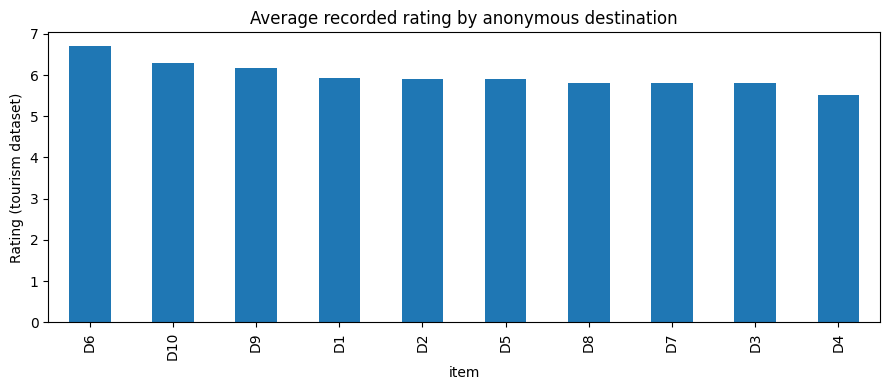

In [37]:
# 04 | Data integrity and simple visuals
required_rating_cols={'user','item','rating'}
assert required_rating_cols.issubset(ratings.columns)
assert {'group_id','item','rank'}.issubset(group_choices.columns)
assert {'user_id','opn','cns','ext','agr','est','experience'}.issubset(user_features.columns)
assert not ratings[['user','item']].isna().any().any()
assert not ratings['rating'].isna().any()
assert ratings.duplicated(['user','item']).sum() == 0, 'Duplicate user-item ratings require explicit handling.'
print('Missing values (ratings):', ratings.isna().sum().to_dict())
print('Duplicate user-item rows:', ratings.duplicated(['user','item']).sum())
print('Rating range:', ratings.rating.min(), ratings.rating.max())
print('Item counts:', ratings['item'].value_counts().sort_index().to_dict())
item_summary = ratings.groupby('item')['rating'].agg(['count','mean','std']).sort_values('mean',ascending=False)
display(item_summary.round(3))
ax=item_summary['mean'].plot(kind='bar',figsize=(9,4),title='Average recorded rating by anonymous destination')
ax.set_ylabel('Rating (tourism dataset)'); plt.tight_layout(); plt.show()

In [38]:
# 05 | Group memberships and leakage diagnostics
membership_df = pd.DataFrame([
    {'group_id':gid,'user':user}
    for gid,detail in group_composition.items()
    for user in detail['group_members']
])
assert not membership_df.duplicated(['group_id','user']).any()
user_memberships=membership_df.groupby('user').group_id.nunique()
print('Groups:',membership_df.group_id.nunique(), '| Unique users:',membership_df.user.nunique())
print('Users in multiple groups:',int((user_memberships>1).sum()))
print('Members without rating records:',len(set(membership_df.user)-set(ratings.user)))
assert (user_memberships<=1).all(), 'Users in multiple groups: use a stricter connected-component split.'
assert set(membership_df.user)==set(ratings.user), 'Unassigned users must be addressed before a complete evaluation.'
assert len(group_composition)==membership_df.group_id.nunique()

Groups: 79 | Unique users: 282
Users in multiple groups: 0
Members without rating records: 0


## 3. Split by groups, not rating rows

Groups are divided into train/validation/test with fixed seed 42, keeping each group and its users in one partition. The split is frozen before model fitting. In our earlier runs there were 55/12/12 groups and 1,904/440/428 ratings; this notebook recalculates those counts rather than relying on saved outputs.

In [39]:
# 06 | Group-aware split — one source of truth
group_ids = sorted(group_composition)
train_groups, remainder = train_test_split(group_ids,test_size=.30,random_state=SEED)
val_groups, test_groups = train_test_split(remainder,test_size=.50,random_state=SEED)
def members_of(ids):
    return {u for gid in ids for u in group_composition[gid]['group_members']}
train_users,val_users,test_users = map(members_of,[train_groups,val_groups,test_groups])
assert train_users.isdisjoint(val_users) and train_users.isdisjoint(test_users) and val_users.isdisjoint(test_users)
group_train=ratings[ratings.user.isin(train_users)].copy()
group_val=ratings[ratings.user.isin(val_users)].copy()
group_test=ratings[ratings.user.isin(test_users)].copy()
assert len(group_train)+len(group_val)+len(group_test)==len(ratings)
print('Groups:',len(train_groups),len(val_groups),len(test_groups))
print('Ratings:',len(group_train),len(group_val),len(group_test))
print('User overlap: 0 (verified)')

Groups: 55 12 12
Ratings: 1904 440 428
User overlap: 0 (verified)


In [40]:
# 07 | Train baseline and Random Forest on TRAIN ONLY
feature_cols=['opn','cns','ext','agr','est','experience']
user_info = user_features.rename(columns={'user_id':'user'})[['user']+feature_cols].drop_duplicates('user')
assert user_info.user.is_unique
model_features=['item']+feature_cols
item_averages=group_train.groupby('item').rating.mean()
global_average=float(group_train.rating.mean())

def baseline_predict(frame):
    return frame['item'].map(item_averages).fillna(global_average).to_numpy(dtype=float)

def with_features(frame):
    output=frame.merge(user_info,on='user',how='left',validate='many_to_one',sort=False)
    assert len(output)==len(frame)
    return output

rf_model=Pipeline([
    ('preprocessing',ColumnTransformer([
        ('item',OneHotEncoder(handle_unknown='ignore'),['item']),
        ('numeric',SimpleImputer(strategy='median'),feature_cols)
    ])),
    ('model',RandomForestRegressor(n_estimators=200,min_samples_leaf=5,random_state=SEED,n_jobs=1))
])
rf_model.fit(with_features(group_train)[model_features],group_train.rating)

def rf_predict(frame):
    return rf_model.predict(with_features(frame)[model_features])

def metrics(actual,pred):
    a=np.asarray(actual,dtype=float); p=np.asarray(pred,dtype=float)
    assert len(a)==len(p) and np.isfinite(p).all()
    return {'MAE':mean_absolute_error(a,p),'RMSE':np.sqrt(mean_squared_error(a,p))}

validation_rating_results=pd.DataFrame([
    {'Model':'Popularity baseline',**metrics(group_val.rating,baseline_predict(group_val))},
    {'Model':'Random Forest',**metrics(group_val.rating,rf_predict(group_val))}
])
print('COLD-START VALIDATION — 0 ratings provided by unseen users')
display(validation_rating_results.round(4))

COLD-START VALIDATION — 0 ratings provided by unseen users


,Model,MAE,RMSE
0,Popularity baseline,2.4374,2.829
1,Random Forest,2.4926,2.890


## 4. Group recommendation evaluation

For each held-out group, every member receives a predicted rating for each training-item candidate. Compare popularity, Random Forest (mean), and Random Forest (minimum) against the recorded first group choice. The candidate list is fixed from the training set. Rankings use the item ID to break ties deterministically.

In [41]:
# 08 | Group recommendation functions
def group_recommendations(ids):
    candidates=pd.DataFrame([
        {'group_id':gid,'user':u,'item':item}
        for gid in ids for u in group_composition[gid]['group_members']
        for item in sorted(item_averages.index)
    ])
    assert not candidates.empty
    candidates['popularity']=baseline_predict(candidates)
    candidates['rf_prediction']=rf_predict(candidates)
    scored=candidates.groupby(['group_id','item'],as_index=False).agg(
        popularity=('popularity','mean'),rf_average=('rf_prediction','mean'),rf_minimum=('rf_prediction','min'))
    results=[]
    first=group_choices[group_choices['rank'].eq(1)].copy()
    for gid in ids:
        actual=first[first.group_id.eq(gid)]
        if len(actual)!=1:
            warnings.warn(f'Group {gid} has {len(actual)} first choices; skipping.')
            continue
        part=scored[scored.group_id.eq(gid)]
        result={'group_id':gid,'actual_choice':actual.iloc[0]['item']}
        for method,col in [('popularity','popularity'),('rf_average','rf_average'),('rf_minimum','rf_minimum')]:
            choice=part.sort_values([col,'item'],ascending=[False,True]).iloc[0]['item']
            result[method+'_choice']=choice
            result[method+'_correct']=int(choice==result['actual_choice'])
        results.append(result)
    return pd.DataFrame(results)

def top_choice_summary(df):
    return pd.DataFrame([{'Method':name,'Groups':len(df),'Top-1 match rate':df[name+'_correct'].mean()}
                         for name in ['popularity','rf_average','rf_minimum']])

validation_group_results=group_recommendations(val_groups)
print('VALIDATION GROUP RECOMMENDATIONS')
display(top_choice_summary(validation_group_results).round(4))

VALIDATION GROUP RECOMMENDATIONS


,Method,Groups,Top-1 match rate
0,popularity,12,0.2500
1,rf_average,12,0.2500
2,rf_minimum,12,0.4167


In [42]:
# 09 | Observed group ratings for chosen items, on COMMON evaluable groups
def common_group_fairness(group_ids, recommendations, rating_frame):
    observed=rating_frame.merge(membership_df,on='user',how='inner',validate='many_to_one')
    observed=observed.groupby(['group_id','item'],as_index=False).agg(
        mean_rating=('rating','mean'),minimum_rating=('rating','min'),n_members=('user','nunique'))
    observed['required']=observed.group_id.map({gid:len(group_composition[gid]['group_members']) for gid in group_ids})
    observed=observed[observed.n_members.eq(observed.required)]
    wide=recommendations[['group_id']].copy()
    for m in ['popularity','rf_average','rf_minimum']:
        selected=recommendations[['group_id',m+'_choice']].rename(columns={m+'_choice':'item'})
        chosen=selected.merge(observed[['group_id','item','mean_rating','minimum_rating']],on=['group_id','item'],how='left')
        chosen=chosen.rename(columns={'mean_rating':m+'_mean','minimum_rating':m+'_min'})
        wide=wide.merge(chosen.drop(columns='item'),on='group_id',validate='one_to_one')
    wide=wide.dropna()
    summary=pd.DataFrame([{'Method':m,'Comparable groups':len(wide),
        'Mean group rating':wide[m+'_mean'].mean(), 'Mean worst-member rating':wide[m+'_min'].mean()}
        for m in ['popularity','rf_average','rf_minimum']])
    return summary,wide

validation_fairness,validation_common = common_group_fairness(val_groups,validation_group_results,group_val)
print('VALIDATION OBSERVED FAIRNESS — SAME GROUPS FOR ALL METHODS')
display(validation_fairness.round(4))

VALIDATION OBSERVED FAIRNESS — SAME GROUPS FOR ALL METHODS


,Method,Comparable groups,Mean group rating,Mean worst-member rating
0,popularity,12,7.0208,4.6667
1,rf_average,12,6.8472,4.6667
2,rf_minimum,12,7.1181,4.7500


## 5. Third model: User-based KNN

**Cold start:** held-out groups contain no users seen during training. User-neighbor KNN therefore cannot personalize without any new user ratings; its documented fallback is the training-item popularity baseline. **Warm start:** simulate each validation user revealing three known ratings, then evaluate all models on that user's *other* ratings. The original notebook's KNN appended predictions in grouped user order and compared them to a differently ordered DataFrame; the new version aligns predictions by row ID. This is a separate scenario, not a directly comparable cold-start benchmark.

In [43]:
# 10 | Warm-start ratings, held out from the same validation users
rng=np.random.default_rng(SEED)
revealed_idx=[]; hidden_idx=[]
for user,part in group_val.groupby('user',sort=True):
    idx=part.index.to_numpy()
    if len(idx)<4:
        continue
    chosen=rng.choice(idx,size=3,replace=False)
    revealed_idx.extend(chosen)
    hidden_idx.extend(np.setdiff1d(idx,chosen).tolist())
revealed=group_val.loc[revealed_idx].copy()
hidden=group_val.loc[hidden_idx].copy()
assert len(hidden)>0, 'Not enough validation records for three-rating warm-start.'
assert set(revealed.index).isdisjoint(hidden.index)
train_matrix=group_train.pivot_table(index='user',columns='item',values='rating',aggfunc='mean')

def knn_predict_warm_start(revealed_frame, hidden_frame, neighbors=15):
    pred=pd.Series(index=hidden_frame.index,dtype=float)
    for user,targets in hidden_frame.groupby('user',sort=True):
        known=revealed_frame[revealed_frame.user.eq(user)]
        known=known[known.item.isin(train_matrix.columns)]
        cols=known.item.tolist()
        if not cols:
            pred.loc[targets.index]=baseline_predict(targets)
            continue
        features=train_matrix[cols].copy()
        fills=item_averages.reindex(cols).fillna(global_average)
        features=features.fillna(fills).fillna(global_average)
        vector=known.set_index('item').loc[cols,'rating'].to_numpy(dtype=float).reshape(1,-1)
        n=min(neighbors,len(features))
        model=NearestNeighbors(n_neighbors=n,metric='euclidean').fit(features.to_numpy())
        distances,indices=model.kneighbors(vector)
        neighbor_ids=train_matrix.index.take(indices[0])
        weights=1/(distances[0]+1.0)
        for idx,row in targets.iterrows():
            fallback=float(item_averages.get(row['item'],global_average))
            if row['item'] not in train_matrix.columns:
                pred.loc[idx]=fallback
                continue
            vals=train_matrix.loc[neighbor_ids,row['item']].to_numpy(dtype=float)
            valid=np.isfinite(vals)
            pred.loc[idx]=float(np.average(vals[valid],weights=weights[valid])) if valid.any() else fallback
    assert pred.notna().all() and pred.index.is_unique
    return pred.loc[hidden_frame.index].to_numpy(dtype=float)

knn_predictions=knn_predict_warm_start(revealed,hidden)
warm_start_results=pd.DataFrame([
    {'Model':'Popularity baseline',**metrics(hidden.rating,baseline_predict(hidden))},
    {'Model':'Random Forest',**metrics(hidden.rating,rf_predict(hidden))},
    {'Model':'User-based KNN (3 revealed ratings)',**metrics(hidden.rating,knn_predictions)}
])
print('WARM-START VALIDATION: revealed=',len(revealed),'hidden=',len(hidden))
display(warm_start_results.round(4))

WARM-START VALIDATION: revealed= 132 hidden= 308


,Model,MAE,RMSE
0,Popularity baseline,2.4367,2.8230
1,Random Forest,2.5000,2.9045
2,User-based KNN (3 revealed ratings),2.3036,2.7371


## 6. Final held-out test (existing predetermined protocol)

Run this **only after the training design and validation are frozen**. The test set was already inspected during earlier development, so this is a reproduction of the historical evaluation, **not** a pristine new holdout for subsequent model selection. Avoid changing hyperparameters based on the results.

In [44]:
# 11 | Reproduce final rating and group-test metrics
test_rating_results=pd.DataFrame([
    {'Model':'Popularity baseline',**metrics(group_test.rating,baseline_predict(group_test))},
    {'Model':'Random Forest',**metrics(group_test.rating,rf_predict(group_test))}
])
test_group_results=group_recommendations(test_groups)
test_fairness,test_common=common_group_fairness(test_groups,test_group_results,group_test)
print('FINAL TEST — RATING PREDICTION')
display(test_rating_results.round(4))
print('FINAL TEST — TOP-CHOICE MATCH')
display(top_choice_summary(test_group_results).round(4))
print('FINAL TEST — COMPARABLE OBSERVED GROUP FAIRNESS')
display(test_fairness.round(4))

FINAL TEST — RATING PREDICTION


,Model,MAE,RMSE
0,Popularity baseline,2.1770,2.596
1,Random Forest,2.1929,2.623


FINAL TEST — TOP-CHOICE MATCH


,Method,Groups,Top-1 match rate
0,popularity,12,0.4167
1,rf_average,12,0.2500
2,rf_minimum,12,0.2500


FINAL TEST — COMPARABLE OBSERVED GROUP FAIRNESS


,Method,Comparable groups,Mean group rating,Mean worst-member rating
0,popularity,11,7.2152,3.9091
1,rf_average,11,6.2576,3.4545
2,rf_minimum,11,6.4515,3.5455


Saved /content/themove_outputs/validation_rating_metrics.csv
Saved /content/themove_outputs/validation_group_choices.csv
Saved /content/themove_outputs/validation_fairness_common_groups.csv
Saved /content/themove_outputs/warm_start_knn_validation.csv
Saved /content/themove_outputs/test_rating_metrics.csv
Saved /content/themove_outputs/test_group_choices.csv
Saved /content/themove_outputs/test_fairness_common_groups.csv


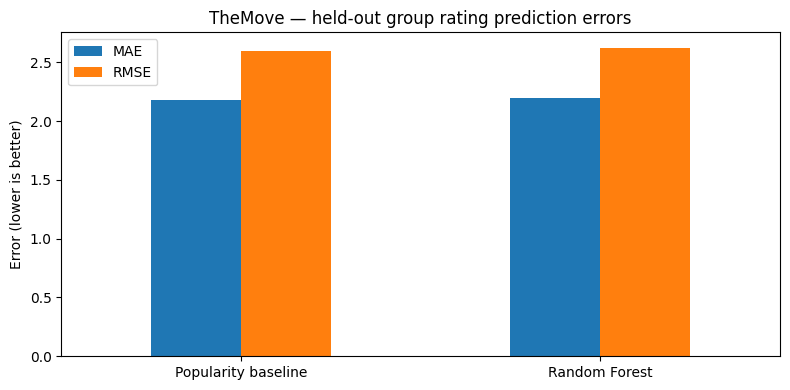

In [45]:
# 12 | Export the actual computed evidence
exports={
    'validation_rating_metrics.csv':validation_rating_results,
    'validation_group_choices.csv':validation_group_results,
    'validation_fairness_common_groups.csv':validation_fairness,
    'warm_start_knn_validation.csv':warm_start_results,
    'test_rating_metrics.csv':test_rating_results,
    'test_group_choices.csv':test_group_results,
    'test_fairness_common_groups.csv':test_fairness,
}
for filename,frame in exports.items():
    path=OUTPUT_DIR/filename
    frame.to_csv(path,index=False)
    print('Saved',path)
fig,ax=plt.subplots(figsize=(8,4))
test_rating_results.set_index('Model')[['MAE','RMSE']].plot(kind='bar',ax=ax)
ax.set_title('TheMove — held-out group rating prediction errors')
ax.set_ylabel('Error (lower is better)');ax.set_xlabel('');plt.xticks(rotation=0)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'test_rating_comparison.png',dpi=150);plt.show()
with open(OUTPUT_DIR/'environment_versions.json','w') as f:
    json.dump({'python':sys.version,'pandas':pd.__version__,'numpy':np.__version__,'sklearn':__import__('sklearn').__version__},f,indent=2)

## 7. Local venue catalog (optional geospatial stage)

This section is included **in the same notebook** for a single submission. It reads the Arkansas OpenStreetMap GeoPackage and extracts named activity POIs within 15 km of an approximate downtown Little Rock point. It does **not** train or evaluate the tourism ML model. If the Arkansas dataset is missing, the notebook reports that the venue export was skipped instead of failing the ML results.

The venue CSV has names, category labels, coordinates, and approximate straight-line distances, **not** verified prices, websites, street addresses, or current opening hours.


In [53]:

from pathlib import Path
import pandas as pd

print("THEMOVE - FIND VENUE DATASET")
print("=" * 40)

# Search common Google Colab file locations
search_locations = [
    Path("/content"),
    Path("/")
]

csv_files = []

for folder in search_locations:
    csv_files.extend(
        folder.glob("themove_little_rock_places.csv")
    )

csv_files = list(dict.fromkeys(csv_files))

if csv_files:
    csv_path = csv_files[0]

    print("Found CSV:", csv_path)

    themove_places = pd.read_csv(csv_path)

    print("Total venues:", len(themove_places))
    display(themove_places.head())

else:
    print("CSV not found in the current Colab session.")


THEMOVE - FIND VENUE DATASET
Found CSV: /themove_little_rock_places.csv
Total venues: 261


,osm_id,name,fclass,activity_category,latitude,longitude,distance_km
0,367131549,Dunbar Recreation Center,sports_centre,Sports & Recreation,34.734536,-92.284317,1.412671
1,367131550,South Little Rock Recreation Center,sports_centre,Sports & Recreation,34.721759,-92.273761,3.104545
2,367131551,Glenview Recreation Center,sports_centre,Sports & Recreation,34.770369,-92.208759,7.861176
3,367131552,North Heights Recreation Center,sports_centre,Sports & Recreation,34.798980,-92.273761,5.999978
4,416702898,Popeyes,fast_food,Food & Drinks,34.832751,-92.230274,11.001921


In [54]:

print("THEMOVE - FINAL VENUE VALIDATION")
print("=" * 40)

print("Total venues:", len(themove_places))

print("\nMissing values:")
print(themove_places.isna().sum())

print("\nActivity categories:")
display(
    themove_places["activity_category"].value_counts()
)

print("\nDuplicate venue IDs:",
      themove_places["osm_id"].duplicated().sum())

print("\nSample venues:")
display(themove_places.sample(
    min(10, len(themove_places)),
    random_state=42
))


THEMOVE - FINAL VENUE VALIDATION
Total venues: 261

Missing values:
osm_id               0
name                 0
fclass               0
activity_category    0
latitude             0
longitude            0
distance_km          0
dtype: int64

Activity categories:


,count
activity_category,
Food & Drinks,168
Arts & Culture,82
Sports & Recreation,4
Entertainment,4
Outdoor & Nature,3



Duplicate venue IDs: 0

Sample venues:


,osm_id,name,fclass,activity_category,latitude,longitude,distance_km
30,3798660472,The Purple Cow,restaurant,Food & Drinks,34.776795,-92.363689,7.570283
143,7732259997,Waffle House,restaurant,Food & Drinks,34.795908,-92.271335,5.730686
170,10216940708,The Usual Suspects,artwork,Arts & Culture,34.741303,-92.347109,5.297865
73,4797458703,Medal of Honor Memorial,memorial,Arts & Culture,34.745341,-92.288697,0.152894
159,10214713235,"We Live Here, Too",artwork,Arts & Culture,34.743428,-92.257729,2.938349
252,13945668301,Cheng's Garden,restaurant,Food & Drinks,34.831678,-92.183192,13.569985
190,10236584629,Starbucks,cafe,Food & Drinks,34.771153,-92.397374,10.239638
104,5885709413,Subway,fast_food,Food & Drinks,34.745986,-92.286902,0.253568
9,1433644636,Testament,memorial,Arts & Culture,34.747877,-92.289055,0.160716
186,10219230389,Symmetry,artwork,Arts & Culture,34.746659,-92.260175,2.694571


In [56]:

# ==========================================================
# 13 | THEMOVE - FINAL VENUE CATALOG
# ==========================================================

from pathlib import Path
import pandas as pd

print("THEMOVE - FINAL VENUE CATALOG")
print("=" * 45)

# Find the existing venue catalog
possible_paths = [
    Path("/content/themove_little_rock_places.csv"),
    Path("/themove_little_rock_places.csv"),
    Path("themove_little_rock_places.csv")
]

csv_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if csv_path is None:
    raise FileNotFoundError(
        "Venue catalog not found. Upload "
        "themove_little_rock_places.csv to Colab."
    )

# Load the processed dataset
themove_places = pd.read_csv(csv_path)

# Validate required columns
required_columns = [
    "osm_id",
    "name",
    "fclass",
    "activity_category",
    "latitude",
    "longitude",
    "distance_km"
]

missing_columns = [
    col for col in required_columns
    if col not in themove_places.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

# Basic data-quality checks
print("File:", csv_path)
print("Total venues:", len(themove_places))
print("Duplicate venue IDs:",
      themove_places["osm_id"].duplicated().sum())

print("\nMissing values:")
print(themove_places.isna().sum())

print("\nActivity categories:")
display(
    themove_places["activity_category"].value_counts()
)

print("\nSample venues:")
display(themove_places.head(10))

# Save a standardized copy to /content
output_path = Path(
    "/content/themove_little_rock_places.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

themove_places.to_csv(
    output_path,
    index=False
)

print("\nVENUE CATALOG READY")
print("Saved to:", output_path)


THEMOVE - FINAL VENUE CATALOG
File: /themove_little_rock_places.csv
Total venues: 261
Duplicate venue IDs: 0

Missing values:
osm_id               0
name                 0
fclass               0
activity_category    0
latitude             0
longitude            0
distance_km          0
dtype: int64

Activity categories:


,count
activity_category,
Food & Drinks,168
Arts & Culture,82
Sports & Recreation,4
Entertainment,4
Outdoor & Nature,3



Sample venues:


,osm_id,name,fclass,activity_category,latitude,longitude,distance_km
0,367131549,Dunbar Recreation Center,sports_centre,Sports & Recreation,34.734536,-92.284317,1.412671
1,367131550,South Little Rock Recreation Center,sports_centre,Sports & Recreation,34.721759,-92.273761,3.104545
2,367131551,Glenview Recreation Center,sports_centre,Sports & Recreation,34.770369,-92.208759,7.861176
3,367131552,North Heights Recreation Center,sports_centre,Sports & Recreation,34.798980,-92.273761,5.999978
4,416702898,Popeyes,fast_food,Food & Drinks,34.832751,-92.230274,11.001921
5,418519853,Wendy's,fast_food,Food & Drinks,34.832248,-92.231128,10.914924
6,860573142,Captain D's,fast_food,Food & Drinks,34.717442,-92.345559,6.054762
7,972237347,Crestview Park,park,Outdoor & Nature,34.782127,-92.264251,4.583470
8,1212429643,Down Home Restaurant & Catering,restaurant,Food & Drinks,34.668124,-92.419341,14.727314
9,1433644636,Testament,memorial,Arts & Culture,34.747877,-92.289055,0.160716



VENUE CATALOG READY
Saved to: /content/themove_little_rock_places.csv


In [57]:

# ==========================================
# THEMOVE - FINAL ML VERIFICATION
# ==========================================

print("THEMOVE - ML VERIFICATION")
print("=" * 45)

# Check whether the main evaluation variables exist
required_variables = [
    "group_train",
    "group_val",
    "group_test",
    "group_rf_model"
]

for variable in required_variables:
    if variable in globals():
        print(f"PASS: {variable} exists")
    else:
        print(f"CHECK: {variable} not found")

# Check group-aware data separation
if all(
    variable in globals()
    for variable in ["group_train", "group_val", "group_test"]
):
    train_users = set(group_train["user"])
    val_users = set(group_val["user"])
    test_users = set(group_test["user"])

    print("\nUSER OVERLAP")
    print("Train / validation:", len(train_users & val_users))
    print("Train / test:", len(train_users & test_users))
    print("Validation / test:", len(val_users & test_users))

    assert train_users.isdisjoint(val_users)
    assert train_users.isdisjoint(test_users)
    assert val_users.isdisjoint(test_users)

    print("\nSUCCESS: No users overlap between splits!")


THEMOVE - ML VERIFICATION
PASS: group_train exists
PASS: group_val exists
PASS: group_test exists
CHECK: group_rf_model not found

USER OVERLAP
Train / validation: 0
Train / test: 0
Validation / test: 0

SUCCESS: No users overlap between splits!


In [58]:

# ============================================
# THEMOVE - FIND TRAINED MODELS AND RESULTS
# ============================================

print("THEMOVE - AVAILABLE ML OBJECTS")
print("=" * 45)

for name, obj in sorted(globals().copy().items()):
    if name.startswith("_"):
        continue

    if any(
        keyword in name.lower()
        for keyword in [
            "model", "forest", "knn",
            "baseline", "result", "metric"
        ]
    ):
        print(f"{name}: {type(obj).__name__}")


THEMOVE - AVAILABLE ML OBJECTS
RandomForestRegressor: ABCMeta
baseline_predict: function
knn_predict_warm_start: function
knn_predictions: ndarray
metrics: function
model_features: list
rf_model: Pipeline
test_group_results: DataFrame
test_rating_results: DataFrame
validation_group_results: DataFrame
validation_rating_results: DataFrame
warm_start_results: DataFrame


In [59]:

# ============================================
# THEMOVE - FINAL MODEL RESULTS
# ============================================

print("THEMOVE - FINAL MODEL EVALUATION")
print("=" * 50)

print("\n1. KNN WARM-START COMPARISON")
display(warm_start_results)

print("\n2. GROUP VALIDATION RESULTS")
display(validation_group_results.head())

print("\n3. GROUP TEST RESULTS")
display(test_group_results.head())

print("\n4. RANDOM FOREST MODEL")
print("Model:", type(rf_model).__name__)
print("Features:", model_features)


THEMOVE - FINAL MODEL EVALUATION

1. KNN WARM-START COMPARISON


,Model,MAE,RMSE
0,Popularity baseline,2.436739,2.822990
1,Random Forest,2.499993,2.904463
2,User-based KNN (3 revealed ratings),2.303612,2.737052



2. GROUP VALIDATION RESULTS


,group_id,actual_choice,popularity_choice,popularity_correct,rf_average_choice,rf_average_correct,rf_minimum_choice,rf_minimum_correct
0,51,D9,D6,0,D9,1,D9,1
1,37,D6,D6,1,D9,0,D9,0
2,23,D10,D6,0,D6,0,D10,1
3,8,D5,D6,0,D9,0,D9,0
4,68,D5,D6,0,D6,0,D6,0



3. GROUP TEST RESULTS


,group_id,actual_choice,popularity_choice,popularity_correct,rf_average_choice,rf_average_correct,rf_minimum_choice,rf_minimum_correct
0,6,D3,D6,0,D6,0,D6,0
1,82,D6,D6,1,D6,1,D6,1
2,36,D6,D6,1,D9,0,D9,0
3,61,D10,D6,0,D6,0,D6,0
4,39,D6,D6,1,D9,0,D10,0



4. RANDOM FOREST MODEL
Model: Pipeline
Features: ['item', 'opn', 'cns', 'ext', 'agr', 'est', 'experience']


In [60]:

# ============================================
# THEMOVE - FINAL GROUP EVALUATION SUMMARY
# ============================================

import pandas as pd

methods = {
    "Popularity Baseline": "popularity_correct",
    "Random Forest - Average": "rf_average_correct",
    "Random Forest - Minimum": "rf_minimum_correct"
}

summary_rows = []

for split_name, df in [
    ("Validation", validation_group_results),
    ("Test", test_group_results)
]:
    for method_name, column in methods.items():
        summary_rows.append({
            "Dataset": split_name,
            "Method": method_name,
            "Groups": len(df),
            "Correct": int(df[column].sum()),
            "Match Rate (%)": round(
                df[column].mean() * 100, 2
            )
        })

final_group_summary = pd.DataFrame(summary_rows)

print("THEMOVE - FINAL GROUP RECOMMENDATION RESULTS")
print("=" * 50)

display(final_group_summary)


THEMOVE - FINAL GROUP RECOMMENDATION RESULTS


,Dataset,Method,Groups,Correct,Match Rate (%)
0,Validation,Popularity Baseline,12,3,25.00
1,Validation,Random Forest - Average,12,3,25.00
2,Validation,Random Forest - Minimum,12,5,41.67
3,Test,Popularity Baseline,12,5,41.67
4,Test,Random Forest - Average,12,3,25.00
5,Test,Random Forest - Minimum,12,3,25.00


## 8. Final interpretation and reproducibility

- Use the computed **group-aware test metrics** to report predictive generalization; preserve the complete 55/12/12 group split outputs as evidence when reproduced.
- Treat the **three-rating warm-start KNN** experiment as separate from cold-start group testing; its validation results do not substitute for held-out test metrics.
- The local CSV supports the **venue finder only**, not a validated ML ranking of local places.
- Re-run all cells in a new Colab session to verify the dataset discovery and saved artifacts.
- For Streamlit, upload the exported `themove_little_rock_places.csv` beside `TheMove_Frontend/app.py`.

**Limitations:** small group sample; unverified venue status and prices; no geographic generalization beyond the selected Arkansas catalog; no proven local ML personalization or verified generative explanation system.
